<a href="https://colab.research.google.com/github/eeeewyz/Multimodal/blob/main/2_CLIP%2BDiffusion_image_generation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# 任务：CLIP的encoder+Diffusion来做图像生成
# Text Prompt
# "A cat sitting on the moon"
#         │
#         ▼
# CLIP Text Encoder
#         │
#         ▼
# Text Hidden States（Text Embeddings）
#         │
#         │                 Random Noise
#         │                 Latent z_t
#         │                     │
#         ▼                     ▼
#         └──────────┬──────────┘
#                    │
#                    ▼
#              Diffusion U-Net
#              ├─ Cross-Attention
#              │  (利用 Text Hidden States 作为条件)
#              └─ Iterative Denoising
#                 (逐步去除 Latent Noise)
#                    │
#                    ▼
#           Denoised Latent z_0
#                    │
#                    ▼
#              VAE Decoder
#                    │
#                    ▼
#             Generated Image

In [2]:
# 安装所需的 Python 库
#
# diffusers：
#   Hugging Face 的 Diffusion 模型库
#   提供 Stable Diffusion Pipeline、U-Net、Scheduler、VAE 等组件
#
# transformers：
#   加载 CLIP Tokenizer 和 CLIP Text Encoder
#
# accelerate：
#   支持 GPU 加速、模型加载和显存管理
#
# safetensors：
#   安全、高效地加载预训练模型权重

!pip install -q diffusers transformers accelerate safetensors

In [3]:
import torch
from diffusers import StableDiffusionPipeline

# 指定 Hugging Face 上的预训练模型
# Stable Diffusion v1.5
model_id = "stable-diffusion-v1-5/stable-diffusion-v1-5"

# 自动检测设备：如果有 GPU 则使用 cuda，否则使用 cpu
device = "cuda" if torch.cuda.is_available() else "cpu"
# CPU 运行不支持 float16，如果是 CPU 则使用 float32 精度
dtype = torch.float16 if device == "cuda" else torch.float32

print(f"当前检测到的设备是: {device}, 使用的数据精度类型是: {dtype}")

# 加载完整的 Stable Diffusion Pipeline
# Pipeline 内部包含：
#   1. CLIP Tokenizer
#   2. CLIP Text Encoder
#   3. Diffusion U-Net
#   4. VAE
#   5. Scheduler

pipe = StableDiffusionPipeline.from_pretrained(
    model_id,
    torch_dtype=dtype,
)

# 将 Pipeline 的模型组件移动到检测到的设备上
pipe = pipe.to(device)

当前检测到的设备是: cuda, 使用的数据精度类型是: torch.float16


/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

In [4]:
# 查看 Stable Diffusion 内部各组件的类型
# （一）
# CLIP Text Encoder
# 作用：将 Text Tokens 转换为 Text Hidden States
print(type(pipe.text_encoder))


# CLIP Tokenizer，一般放在text encoder之前
print(type(pipe.tokenizer))

<class 'transformers.models.clip.modeling_clip.CLIPTextModel'>
<class 'transformers.models.clip.tokenization_clip.CLIPTokenizer'>


In [5]:
# Diffusion U-Net
# 作用：预测 Latent 中的噪声
print(type(pipe.unet))


# VAE
# 作用：
#   Encoder：Image → Latent
#   Decoder：Latent → Image
print(type(pipe.vae))


# Scheduler
# 作用：根据模型预测的噪声，逐步更新 Latent
print(type(pipe.scheduler))

<class 'diffusers.models.unets.unet_2d_condition.UNet2DConditionModel'>
<class 'diffusers.models.autoencoders.autoencoder_kl.AutoencoderKL'>
<class 'diffusers.schedulers.scheduling_pndm.PNDMScheduler'>


In [18]:
# 定义文本提示词
prompt = "a black cat is on the bed"
# max_length=77：
#   Stable Diffusion v1.5 使用的 CLIP 最大序列长度为 77
#
# truncation=True：
#   超过最大长度的 Token 会被截断

inputs = pipe.tokenizer(
    prompt,
    padding="max_length",
    max_length=77,
    truncation=True,
    return_tensors="pt",
)


input_ids = inputs.input_ids.to("cuda")


# 查看输入维度
# [Batch Size, Sequence Length]

print(input_ids.shape)

# torch.Size([1, 77])


# 查看 Token IDs
print(input_ids)

torch.Size([1, 77])
tensor([[49406,   320,  1449,  2368,   533,   525,   518,  2722, 49407, 49407,
         49407, 49407, 49407, 49407, 49407, 49407, 49407, 49407, 49407, 49407,
         49407, 49407, 49407, 49407, 49407, 49407, 49407, 49407, 49407, 49407,
         49407, 49407, 49407, 49407, 49407, 49407, 49407, 49407, 49407, 49407,
         49407, 49407, 49407, 49407, 49407, 49407, 49407, 49407, 49407, 49407,
         49407, 49407, 49407, 49407, 49407, 49407, 49407, 49407, 49407, 49407,
         49407, 49407, 49407, 49407, 49407, 49407, 49407, 49407, 49407, 49407,
         49407, 49407, 49407, 49407, 49407, 49407, 49407]], device='cuda:0')


In [19]:
# 使用 CLIP Text Encoder 提取文本特征
#
# torch.no_grad()：
#   禁用梯度计算
#   因为当前只进行推理，不训练模型
with torch.no_grad():
    text_outputs = pipe.text_encoder(input_ids)


# 提取最后一层 Hidden States
text_embeddings = text_outputs.last_hidden_state


# 查看 Text Embeddings 的维度，
print(text_embeddings.shape)


torch.Size([1, 77, 768])


In [20]:
# Stable Diffusion 完整推理
#
# pipe()：
#   调用完整 Text-to-Image Pipeline

# num_inference_steps=25：
#   设置 Scheduler 的去噪步数
#   通常步数越多，计算耗时越长
#   但并不保证生成质量一定更好

# guidance_scale=7.5：
#   Classifier-Free Guidance（CFG）强度
#   控制生成过程对文本条件的遵循程度
#
# torch.inference_mode()：
#   禁用梯度计算并进一步优化推理开销

with torch.inference_mode():
    outputs = pipe(
        prompt=prompt,
        num_inference_steps=25,
        guidance_scale=7.5,
    )

  0%|          | 0/25 [00:00<?, ?it/s]

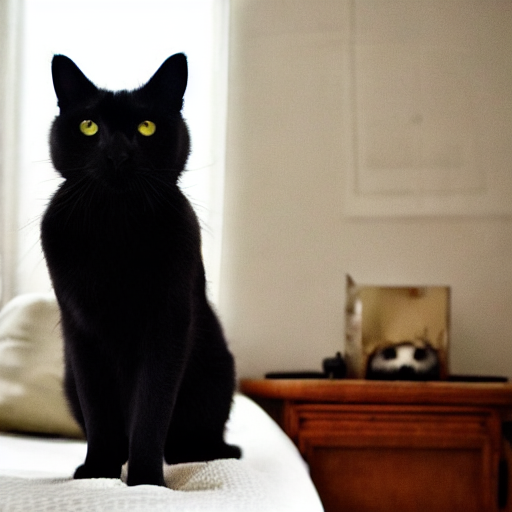

In [21]:
# 提取生成结果
#
# outputs：
#   StableDiffusionPipelineOutput 对象
#
# outputs.images：
#   生成的图片列表
#
# [0]：
#   提取第一张生成图片

image = outputs.images[0]


# 在 Colab 中显示生成图片
display(image)